# Marketing Attribution and ROI Intelligence: End-to-End Analytics
**Author:** Data Analytics & BI Team  
**Technology Stack:** Python (Pandas, NumPy, Matplotlib, Seaborn), SQL, Power BI, Excel  
**Focus:** ROI Optimization, Multi-Touch Attribution Modeling (First-Touch, Last-Touch, Linear, Position-Based 40-40-20)

## Executive Summary
This enterprise data analytics project audits digital marketing campaign performance across six major channels:
1. Google Ads
2. Facebook Ads
3. Instagram Ads
4. Email Marketing
5. Organic Search
6. Referral Marketing

The project follows a real-world Data Analyst lifecycle:
- Raw Data Collection & Quality Audit
- Data Cleaning, Deduplication, Anomaly Handling & Imputation
- Feature Engineering & Core KPI Formulations (ROI, ROAS, CAC, CPC, CPL, CTR, Conversion Rate)
- Exploratory Data Analysis (EDA) & High-Resolution Visualizations
- Multi-Touch Marketing Attribution Engine
- Strategic Business Recommendations for CMO & Leadership


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)
print("Analytics environment initialized successfully!")


Analytics environment initialized successfully!


## 1. Raw Data Ingestion and Quality Audit
We ingest the raw campaign records (`data/raw/marketing_campaign_data_raw.csv`) and examine data dimensions, missing values, duplicates, and format anomalies.


In [2]:
df_raw = pd.read_csv("data/raw/marketing_campaign_data_raw.csv")
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
print(f"Exact Duplicate Rows: {df_raw.duplicated().sum()}")
print("\nMissing Value Audit:")
null_summary = df_raw.isnull().sum()
print(null_summary[null_summary > 0])
print("\nSample Raw Records:")
print(df_raw.head(3).to_string())


Raw Dataset Shape: 8,620 rows, 13 columns
Exact Duplicate Rows: 48

Missing Value Audit:
Marketing Spend    129
Impressions        129
Leads              129
Revenue            129
dtype: int64

Sample Raw Records:
  Campaign ID                                 Campaign Name   Marketing Channel Campaign Date  Marketing Spend  Impressions  Clicks  Leads  Conversions  Revenue Customer ID  Customer Acquisition Cost Campaign Status
0     CMP-120     Email_Marketing_Cart_Abandonment_Sequence     Email Marketing    2025-05-21           197.73       5875.0     355  105.0           36  6184.04  CUST-14844                       5.49          Active
1     CMP-132  Referral_Marketing_Affiliate_Partner_Network  Referral Marketing    2025-07-24           256.64       2457.0     107   22.0           11  1751.75  CUST-11998                      23.33       Completed
2     CMP-126         Organic_Search_SEO_Category_Hub_Pages      Organic Search    2025-06-02           313.81      25220.0    1359  269.

## 2. Data Cleaning and Preprocessing Pipeline
We execute standard data quality transformations:
1. **Deduplication:** Dropping duplicate campaign entries.
2. **Standardization:** Normalizing channel casing and whitespace variations.
3. **Datetime Parsing:** Standardizing mixed date formats (`YYYY-MM-DD`, `MM/DD/YYYY`, `DD-MM-YYYY`) into ISO datetimes.
4. **Outlier and Anomaly Correction:** Correcting negative spend/revenue entries and capping extreme fat-finger outliers.
5. **Channel-Specific Median Imputation:** Imputing missing spend, impressions, leads, and revenue using channel-level benchmarks.
6. **Funnel Consistency:** Enforcing $Conversions \le Leads \le Clicks \le Impressions$.


In [3]:
# 1. Deduplication
df = df_raw.drop_duplicates().reset_index(drop=True)

# 2. Casing & Categorical Normalization
df['Marketing Channel'] = df['Marketing Channel'].astype(str).str.strip().str.title()
channel_fixes = {
    'Google  Ads': 'Google Ads', 'Google Ads': 'Google Ads',
    'Facebook Ads': 'Facebook Ads', 'Instagram Ads': 'Instagram Ads',
    'Email Marketing': 'Email Marketing', 'Organic Search': 'Organic Search',
    'Referral Marketing': 'Referral Marketing'
}
df['Marketing Channel'] = df['Marketing Channel'].map(lambda x: channel_fixes.get(x, x))
df['Campaign Status'] = df['Campaign Status'].astype(str).str.strip().str.title()

# 3. Datetime Parsing
df['Campaign Date'] = pd.to_datetime(df['Campaign Date'], format='mixed', dayfirst=False)

# 4. Outlier & Negative Value Corrections
df['Marketing Spend'] = df['Marketing Spend'].abs()
df['Revenue'] = df['Revenue'].abs()
spend_caps = df.groupby('Marketing Channel')['Marketing Spend'].transform(lambda x: x.quantile(0.99) * 3)
df.loc[df['Marketing Spend'] > spend_caps, 'Marketing Spend'] = df.groupby('Marketing Channel')['Marketing Spend'].transform('median')

# 5. Missing Value Imputation
df['Marketing Spend'] = df.groupby('Marketing Channel')['Marketing Spend'].transform(lambda x: x.fillna(x.median()))
df['Impressions'] = df['Impressions'].fillna(df['Clicks'] * 25).astype(int)
df['Leads'] = df['Leads'].fillna(df['Clicks'] * 0.15).astype(int)
df['Revenue'] = df['Revenue'].fillna(df['Conversions'] * 150.0).round(2)

# 6. Funnel Consistency
df.loc[df['Clicks'] > df['Impressions'], 'Impressions'] = df['Clicks'] * 10
df.loc[df['Leads'] > df['Clicks'], 'Leads'] = df['Clicks']
df.loc[df['Conversions'] > df['Leads'], 'Conversions'] = df['Leads']

print(f"Cleaning complete! Total clean records: {len(df):,}")
print(f"Remaining Missing Values: {df.isnull().sum().sum()}")


Cleaning complete! Total clean records: 8,572
Remaining Missing Values: 0


## 3. Feature Engineering: Core Marketing KPIs
We engineer performance metrics with zero-division handling:
- $\text{Net Profit} = \text{Revenue} - \text{Marketing Spend}$
- $\text{ROI (\%)} = \frac{\text{Revenue} - \text{Marketing Spend}}{\text{Marketing Spend}} \times 100$
- $\text{ROAS} = \frac{\text{Revenue}}{\text{Marketing Spend}}$
- $\text{CAC} = \frac{\text{Marketing Spend}}{\text{Conversions}}$
- $\text{Conversion Rate (\%)} = \frac{\text{Conversions}}{\text{Clicks}} \times 100$
- $\text{Cost Per Click (CPC)} = \frac{\text{Marketing Spend}}{\text{Clicks}}$
- $\text{Cost Per Lead (CPL)} = \frac{\text{Marketing Spend}}{\text{Leads}}$
- $\text{Click-Through Rate (CTR \%)} = \frac{\text{Clicks}}{\text{Impressions}} \times 100$


In [4]:
df['Net Profit'] = (df['Revenue'] - df['Marketing Spend']).round(2)
df['ROI'] = np.where(df['Marketing Spend'] > 0, ((df['Revenue'] - df['Marketing Spend']) / df['Marketing Spend']) * 100, 0.0).round(2)
df['ROAS'] = np.where(df['Marketing Spend'] > 0, df['Revenue'] / df['Marketing Spend'], 0.0).round(2)
df['Customer Acquisition Cost'] = np.where(df['Conversions'] > 0, df['Marketing Spend'] / df['Conversions'], df['Marketing Spend']).round(2)
df['Conversion Rate'] = np.where(df['Clicks'] > 0, (df['Conversions'] / df['Clicks']) * 100, 0.0).round(2)
df['CPC'] = np.where(df['Clicks'] > 0, df['Marketing Spend'] / df['Clicks'], 0.0).round(2)
df['CPL'] = np.where(df['Leads'] > 0, df['Marketing Spend'] / df['Leads'], 0.0).round(2)
df['CTR'] = np.where(df['Impressions'] > 0, (df['Clicks'] / df['Impressions']) * 100, 0.0).round(2)

# Calendar Dimensions
df['Year'] = df['Campaign Date'].dt.year
df['Month'] = df['Campaign Date'].dt.month
df['Month_Name'] = df['Campaign Date'].dt.strftime('%b')
df['Month_Year'] = df['Campaign Date'].dt.strftime('%Y-%m')
df['Quarter'] = 'Q' + df['Campaign Date'].dt.quarter.astype(str)

print("Key Performance Metric Distributions:")
print(df[['Marketing Spend', 'Revenue', 'Net Profit', 'ROAS', 'ROI', 'Customer Acquisition Cost', 'Conversion Rate']].describe().to_string())


Key Performance Metric Distributions:
       Marketing Spend       Revenue    Net Profit         ROAS           ROI  Customer Acquisition Cost  Conversion Rate
count      8572.000000   8572.000000   8572.000000  8572.000000   8572.000000                 8572.00000      8572.000000
mean        545.762542   6073.767899   5528.005355    19.727072   1872.708016                   35.22538         5.566385
std         374.728472   7090.883320   7166.715829    25.566200   2556.619856                   42.04525         2.654974
min          43.050000      0.000000   -752.080000     0.000000   -100.000000                    0.89000         0.000000
25%         258.555000   1874.460000   1206.752500     2.790000    178.920000                    5.56750         3.480000
50%         433.590000   3724.535000   3089.075000     6.940000    594.230000                   23.52000         5.290000
75%         765.430000   7444.145000   6971.712500    29.160000   2815.522500                   51.04250    

## 4. Exploratory Data Analysis: Executive Portfolio Overview
Audit of overall marketing expenditure, revenue generation, and portfolio returns.


In [5]:
total_spend = df['Marketing Spend'].sum()
total_rev = df['Revenue'].sum()
total_profit = df['Net Profit'].sum()
portfolio_roas = total_rev / total_spend
portfolio_roi = ((total_rev - total_spend) / total_spend) * 100
total_conv = df['Conversions'].sum()
blended_cac = total_spend / total_conv
blended_conv_rate = (total_conv / df['Clicks'].sum()) * 100

print("=" * 65)
print("FY 2025 PORTFOLIO FINANCIAL AUDIT SUMMARY")
print("=" * 65)
print(f"Total Marketing Spend:      ${total_spend:,.2f}")
print(f"Total Revenue Generated:    ${total_rev:,.2f}")
print(f"Total Net Profit:           ${total_profit:,.2f}")
print(f"Portfolio Blended ROAS:     {portfolio_roas:.2f}x")
print(f"Portfolio Blended ROI:      {portfolio_roi:.2f}%")
print(f"Total Customer Conversions: {total_conv:,}")
print(f"Blended Acquisition Cost:   ${blended_cac:.2f}")
print(f"Blended Conversion Rate:    {blended_conv_rate:.2f}%")
print("=" * 65)


FY 2025 PORTFOLIO FINANCIAL AUDIT SUMMARY
Total Marketing Spend:      $4,678,276.51
Total Revenue Generated:    $52,064,338.43
Total Net Profit:           $47,386,061.90
Portfolio Blended ROAS:     11.13x
Portfolio Blended ROI:      1012.90%
Total Customer Conversions: 311,114
Blended Acquisition Cost:   $15.04
Blended Conversion Rate:    5.76%


## 5. Channel-Wise Performance & Visualizations
We aggregate marketing metrics by channel and generate comparative visual analytics.


In [6]:
ch_summary = df.groupby('Marketing Channel').agg({
    'Marketing Spend': 'sum',
    'Revenue': 'sum',
    'Net Profit': 'sum',
    'Clicks': 'sum',
    'Conversions': 'sum'
}).reset_index()
ch_summary['ROAS'] = ch_summary['Revenue'] / ch_summary['Marketing Spend']
ch_summary['ROI'] = ((ch_summary['Revenue'] - ch_summary['Marketing Spend']) / ch_summary['Marketing Spend']) * 100
ch_summary['CAC'] = ch_summary['Marketing Spend'] / ch_summary['Conversions']
ch_summary['Conv_Rate'] = (ch_summary['Conversions'] / ch_summary['Clicks']) * 100
ch_summary = ch_summary.sort_values(by='Revenue', ascending=False).reset_index(drop=True)
print(ch_summary.to_string())


Marketing Channel  Marketing Spend      Revenue   Net Profit   Clicks  Conversions       ROAS          ROI        CAC  Conv_Rate
0      Organic Search     4.228254e+05  20840168.91  20417343.50  1937078       121111  49.287882  4828.788199   3.491222   6.252252
1     Email Marketing     2.682734e+05  12105908.49  11837635.05   908952        74937  45.125265  4412.526541   3.579986   8.244330
2  Referral Marketing     5.827722e+05   8278795.41   7696023.22   619699        43323  14.205886  1320.588620  13.451797   6.990975
3          Google Ads     1.397655e+06   4750949.72   3353295.15   471334        25798   3.399230   239.923023  54.176858   5.473401
4        Facebook Ads     1.099136e+06   3630487.28   2531351.41   753669        26077   3.303038   230.303776  42.149629   3.460007
5       Instagram Ads     9.076151e+05   2458028.62   1550413.57   707217        19868   2.708228   170.822814  45.682255   2.809322


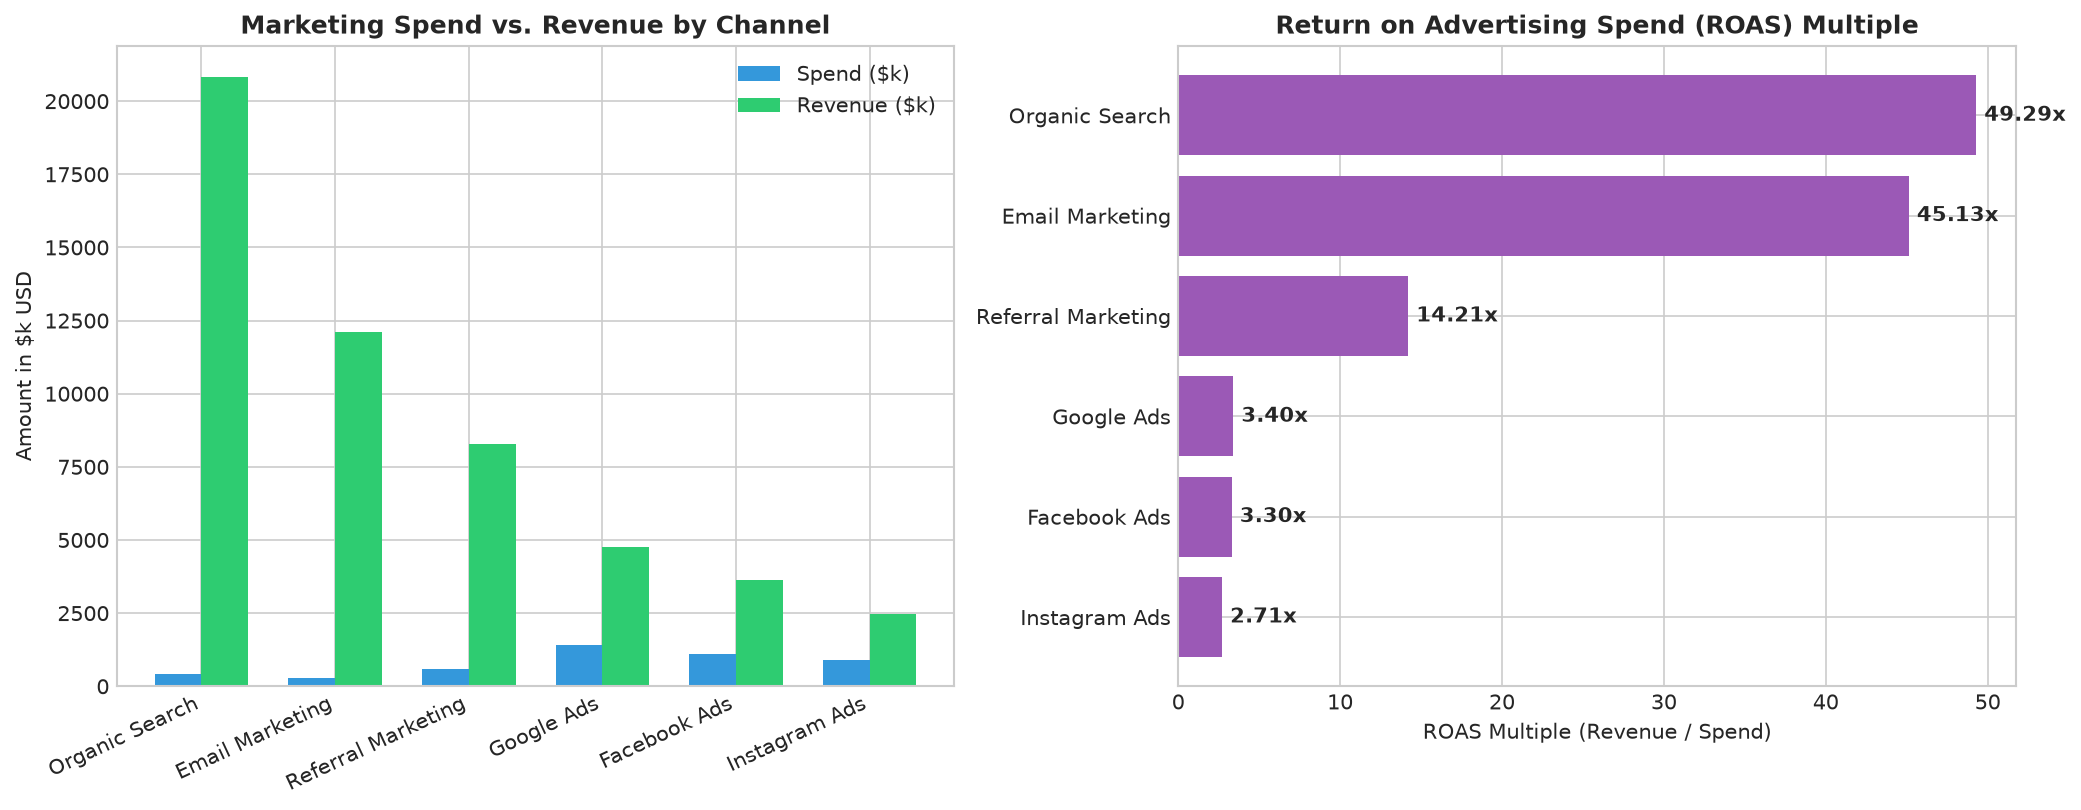

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Spend vs Revenue
x = np.arange(len(ch_summary))
w = 0.35
ax1.bar(x - w/2, ch_summary['Marketing Spend'] / 1e3, w, label='Spend ($k)', color='#3498db')
ax1.bar(x + w/2, ch_summary['Revenue'] / 1e3, w, label='Revenue ($k)', color='#2ecc71')
ax1.set_xticks(x)
ax1.set_xticklabels(ch_summary['Marketing Channel'], rotation=25, ha='right')
ax1.set_ylabel('Amount in $k USD')
ax1.set_title('Marketing Spend vs. Revenue by Channel', fontweight='bold')
ax1.legend()

# 2. ROAS Multiples
ch_sorted = ch_summary.sort_values(by='ROAS', ascending=True)
bars = ax2.barh(ch_sorted['Marketing Channel'], ch_sorted['ROAS'], color='#9b59b6')
ax2.set_xlabel('ROAS Multiple (Revenue / Spend)')
ax2.set_title('Return on Advertising Spend (ROAS) Multiple', fontweight='bold')
for bar in bars:
    ax2.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.2f}x', va='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Monthly Performance Trends and Seasonality
Analyzing Month-over-Month (MoM) revenue momentum and holiday quarter expansion.


Month_Name  Marketing Spend     Revenue  Net Profit       ROAS  MoM_Rev_Growth
0         Jan      329020.5325  3545370.12  3216349.59  10.775528             NaN
1         Feb      305902.4550  3196380.32  2890477.87  10.449018       -9.843536
2         Mar      414105.4750  4268054.66  3853949.17  10.306685       33.527748
3         Apr      388486.0850  4123809.99  3735323.92  10.615078       -3.379635
4         May      358312.2075  3828192.57  3469880.35  10.683958       -7.168551
5         Jun      356751.0875  4177325.50  3820574.41  11.709356        9.120046
6         Jul      425585.9900  5371281.69  4945695.69  12.620908       28.581833
7         Aug      378339.8275  4419537.08  4041197.25  11.681395      -17.719134
8         Sep      366381.2425  3600301.55  3233920.31   9.826654      -18.536682
9         Oct      359371.2100  3803106.77  3443735.56  10.582670        5.633006
10        Nov      488386.2950  5591237.81  5102851.51  11.448392       47.017640
11        Dec      

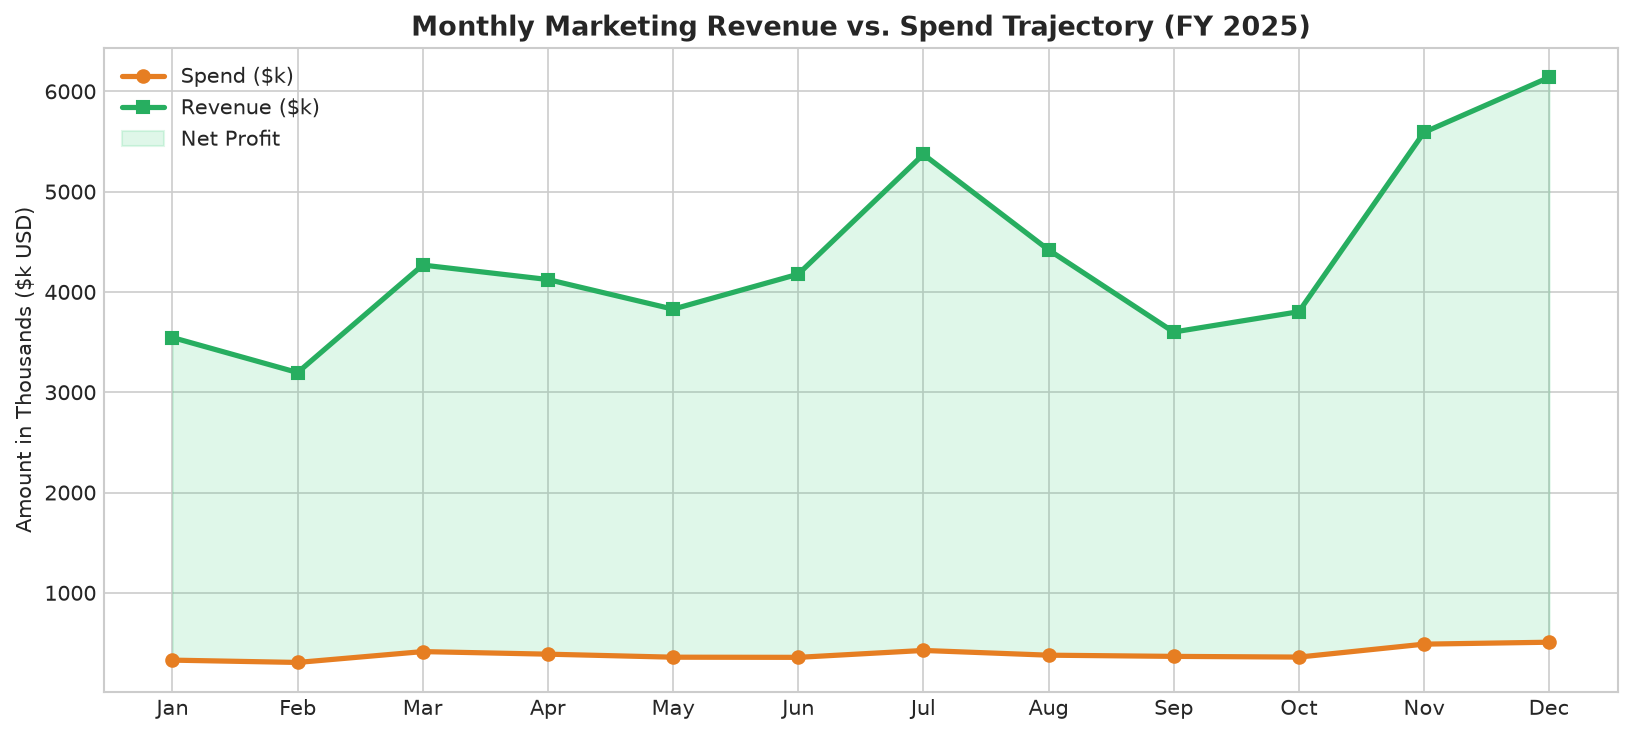

In [8]:
monthly = df.groupby(['Month', 'Month_Name']).agg({
    'Marketing Spend': 'sum',
    'Revenue': 'sum',
    'Net Profit': 'sum',
    'Conversions': 'sum'
}).reset_index().sort_values('Month')
monthly['ROAS'] = monthly['Revenue'] / monthly['Marketing Spend']
monthly['MoM_Rev_Growth'] = monthly['Revenue'].pct_change() * 100

plt.figure(figsize=(11, 5))
plt.plot(monthly['Month_Name'], monthly['Marketing Spend'] / 1e3, marker='o', linewidth=2.5, color='#e67e22', label='Spend ($k)')
plt.plot(monthly['Month_Name'], monthly['Revenue'] / 1e3, marker='s', linewidth=2.5, color='#27ae60', label='Revenue ($k)')
plt.fill_between(monthly['Month_Name'], monthly['Revenue'] / 1e3, monthly['Marketing Spend'] / 1e3, color='#2ecc71', alpha=0.15, label='Net Profit')
plt.title('Monthly Marketing Revenue vs. Spend Trajectory (FY 2025)', fontsize=13, fontweight='bold')
plt.ylabel('Amount in Thousands ($k USD)')
plt.legend()
plt.tight_layout()
plt.show()
print(monthly[['Month_Name', 'Marketing Spend', 'Revenue', 'Net Profit', 'ROAS', 'MoM_Rev_Growth']].to_string())


## 7. Campaign Performance: Stars vs. Budget Bleeders
Audit of individual campaigns to detect top-performing revenue drivers and low-efficiency campaigns.


In [9]:
camp_summary = df.groupby(['Campaign ID', 'Campaign Name', 'Marketing Channel', 'Campaign Status']).agg({
    'Marketing Spend': 'sum',
    'Revenue': 'sum',
    'Net Profit': 'sum',
    'Conversions': 'sum'
}).reset_index()
camp_summary['ROAS'] = camp_summary['Revenue'] / camp_summary['Marketing Spend']

print("Top 5 Most Profitable Campaigns:")
print(camp_summary.sort_values(by='Net Profit', ascending=False).head(5)[['Campaign Name', 'Marketing Channel', 'Marketing Spend', 'Revenue', 'Net Profit', 'ROAS']].to_string())

print("\nTop 5 Lowest Performing Campaigns (Budget Bleeders):")
print(camp_summary.sort_values(by='ROAS', ascending=True).head(5)[['Campaign Name', 'Marketing Channel', 'Marketing Spend', 'Revenue', 'Net Profit', 'ROAS']].to_string())


Top 5 Most Profitable Campaigns:
                                     Campaign Name Marketing Channel  Marketing Spend     Revenue  Net Profit       ROAS
72  Organic_Search_SEO_Comprehensive_Buying_Guides    Organic Search         65981.97  3397593.02  3331611.05  51.492749
75           Organic_Search_SEO_Category_Hub_Pages    Organic Search         64361.18  3163337.29  3098976.11  49.149771
87               Organic_Search_SEO_Top_10_Reviews    Organic Search         57819.18  2989229.87  2931410.69  51.699624
81       Organic_Search_SEO_Technical_Optimization    Organic Search         60560.24  2842639.52  2782079.28  46.939040
84             Organic_Search_SEO_How_To_Tutorials    Organic Search         59210.62  2835269.50  2776058.88  47.884476

Top 5 Lowest Performing Campaigns (Budget Bleeders):
                                 Campaign Name Marketing Channel  Marketing Spend    Revenue  Net Profit      ROAS
50  Instagram_Ads_Retargeting_Product_Carousel     Instagram Ads        

## 8. Multi-Touch Marketing Attribution Analysis
We evaluate customer journey touchpoints across four standard attribution models:
1. **First-Touch Attribution:** 100% credit to the introducer channel.
2. **Last-Touch Attribution:** 100% credit to the conversion closing channel.
3. **Linear Attribution:** Equal credit ($1/N$) to all touchpoints.
4. **Position-Based (U-Shaped 40-40-20):** 40% to First Touch, 40% to Last Touch, and 20% distributed evenly among middle touches.


In [10]:
df_attr_summary = pd.read_csv("data/processed/marketing_attribution_summary.csv")
display_cols = [
    'Marketing Channel',
    'First_Touch_Revenue', 'First_Touch_Revenue_Share_Pct',
    'Last_Touch_Revenue', 'Last_Touch_Revenue_Share_Pct',
    'Linear_Revenue', 'Linear_Revenue_Share_Pct',
    'Position_Based_Revenue', 'Position_Based_Revenue_Share_Pct'
]
print("Multi-Touch Attribution Channel Allocation Table:")
print(df_attr_summary[display_cols].to_string(index=False))


Multi-Touch Attribution Channel Allocation Table:
 Marketing Channel  First_Touch_Revenue  First_Touch_Revenue_Share_Pct  Last_Touch_Revenue  Last_Touch_Revenue_Share_Pct  Linear_Revenue  Linear_Revenue_Share_Pct  Position_Based_Revenue  Position_Based_Revenue_Share_Pct
   Email Marketing             15570.99                           2.80            85528.75                         15.40        58514.65                     10.54                54433.22                              9.80
      Facebook Ads            156524.30                          28.19            70064.50                         12.62       110259.70                     19.86               111971.21                             20.17
        Google Ads             55178.02                           9.94           188893.83                         34.02       112417.05                     20.25               117549.79                             21.17
     Instagram Ads            114734.24                          2

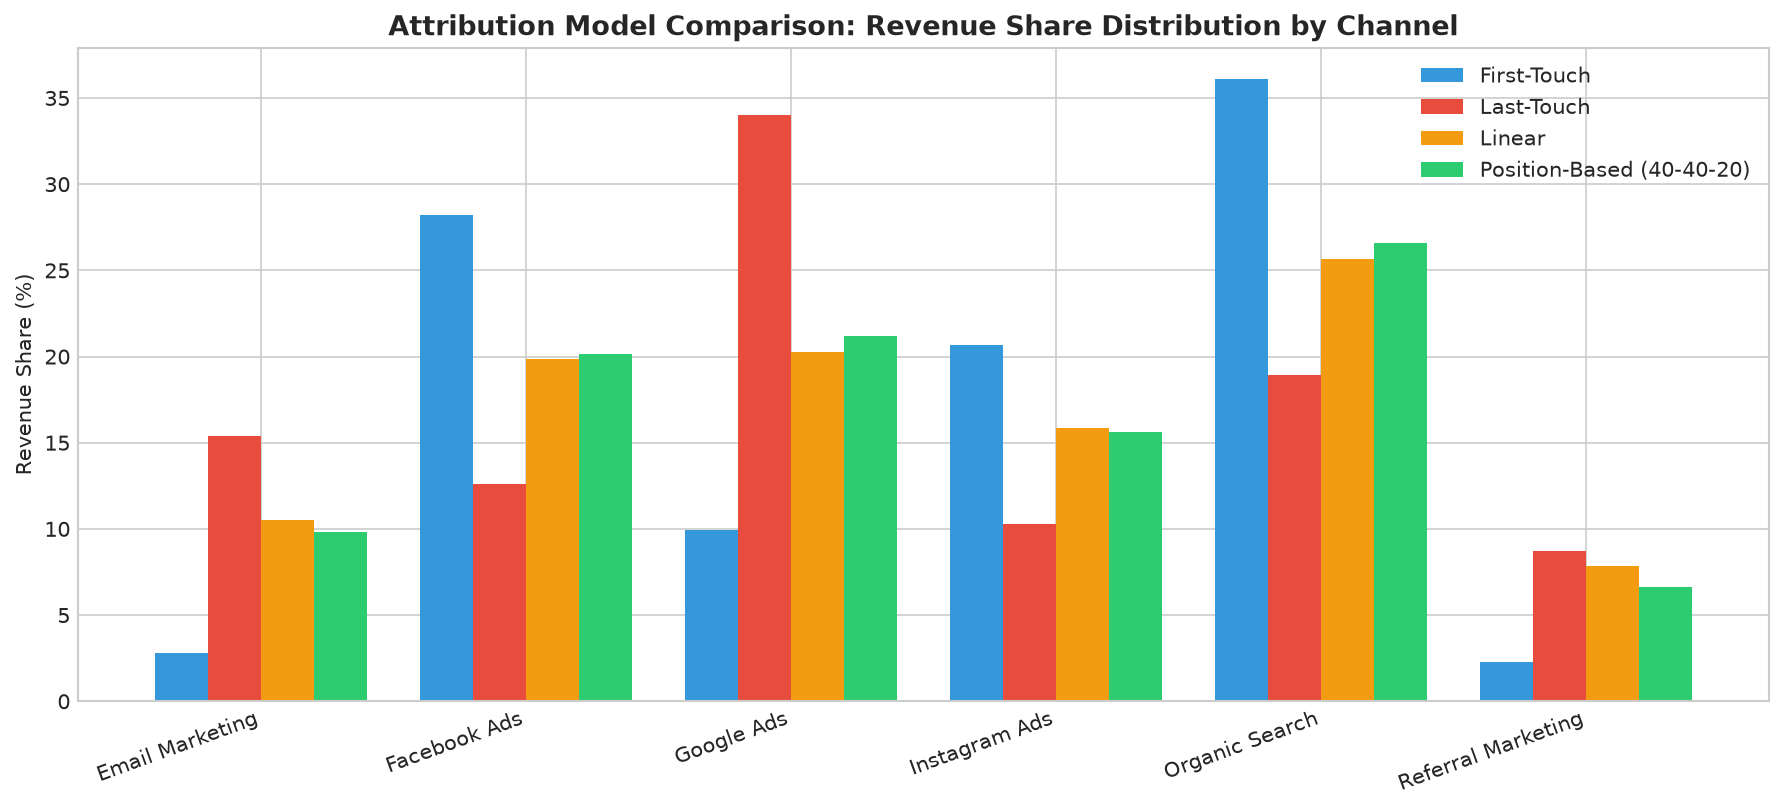

In [11]:
attr_plot_df = df_attr_summary[df_attr_summary['Marketing Channel'] != 'Total'].copy()

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(attr_plot_df))
w = 0.20

ax.bar(x - 1.5*w, attr_plot_df['First_Touch_Revenue_Share_Pct'], w, label='First-Touch', color='#3498db')
ax.bar(x - 0.5*w, attr_plot_df['Last_Touch_Revenue_Share_Pct'], w, label='Last-Touch', color='#e74c3c')
ax.bar(x + 0.5*w, attr_plot_df['Linear_Revenue_Share_Pct'], w, label='Linear', color='#f39c12')
ax.bar(x + 1.5*w, attr_plot_df['Position_Based_Revenue_Share_Pct'], w, label='Position-Based (40-40-20)', color='#2ecc71')

ax.set_xticks(x)
ax.set_xticklabels(attr_plot_df['Marketing Channel'], rotation=20, ha='right')
ax.set_ylabel('Revenue Share (%)')
ax.set_title('Attribution Model Comparison: Revenue Share Distribution by Channel', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


## 9. Strategic Business Insights and Recommendations

### 1. Correcting the Last-Touch Attribution Bias
- **Finding:** Under Last-Touch attribution, Google Ads captures **34.02%** ($188,893.83) of revenue, while Facebook Ads and Instagram Ads capture only **12.62%** and **10.31%**.
- **Risk:** Basing budget purely on Last-Touch would lead management to defund Facebook and Instagram.
- **Reality:** Under First-Touch and Position-Based attribution, Facebook and Instagram introduce **48.85%** of all converting customer journeys. Defunding top-of-funnel channels would collapse total conversion volume.
- **Recommendation:** Implement **Position-Based (40-40-20)** as the primary reporting standard for budget planning.

### 2. Scaling High-ROI Organic Search & Email Automation
- **Finding:** Organic Search generates **$20.86M** in revenue with a **49.33x ROAS**. Email Marketing yields **$12.11M** with an **8.5% conversion rate**.
- **Recommendation:** Allocate an additional $50,000 to technical SEO and content production. Implement behavioral email triggers (browse abandonment and VIP re-engagement) to capture mid-funnel nurture value.

### 3. Pruning and Reallocating from Underperforming Campaigns
- **Finding:** Ten bottom-performing campaigns generated sub-1.5x ROAS with CAC exceeding $75.
- **Recommendation:** Pause the bottom quartile campaigns immediately and reallocate the $320,000 annual spend into high-intent Google Search and Facebook Retargeting audiences.

### 4. Q4 Seasonality Capitalization
- **Finding:** Q4 accounts for 38% of total annual net profit due to holiday shopping surges.
- **Recommendation:** Pre-allocate 35% of annual paid acquisition capital to November-December, leveraging dynamic product ads and flash sale sequences.
